In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
plt.style.use(['science', 'no-latex', 'ieee'])

import scipy as sp
import os
from scipy.optimize import curve_fit
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic
from wong import sigma
import findiff as fd

#size=(6, 6)
#plt.rcParams.update({'figure.figsize': size})
#plt.rcParams.update({'font.size': 20})

#sp.__version__

In [2]:
#### SYSTEM ####

dirname = "/Users/aaronphilip/Senior Thesis/barrier-distribution-sample/16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0

### Fitting Wong formula to Morton 1999 via $\chi^2$ regression

We will consider experiments using these parameters

Best-fit parameters:
  E0    = 73.3846 ± 0.0047 MeV
  R0    = 10.2260 ± 0.0078 fm
  hbarw = 4.8410 ± 0.0074 MeV


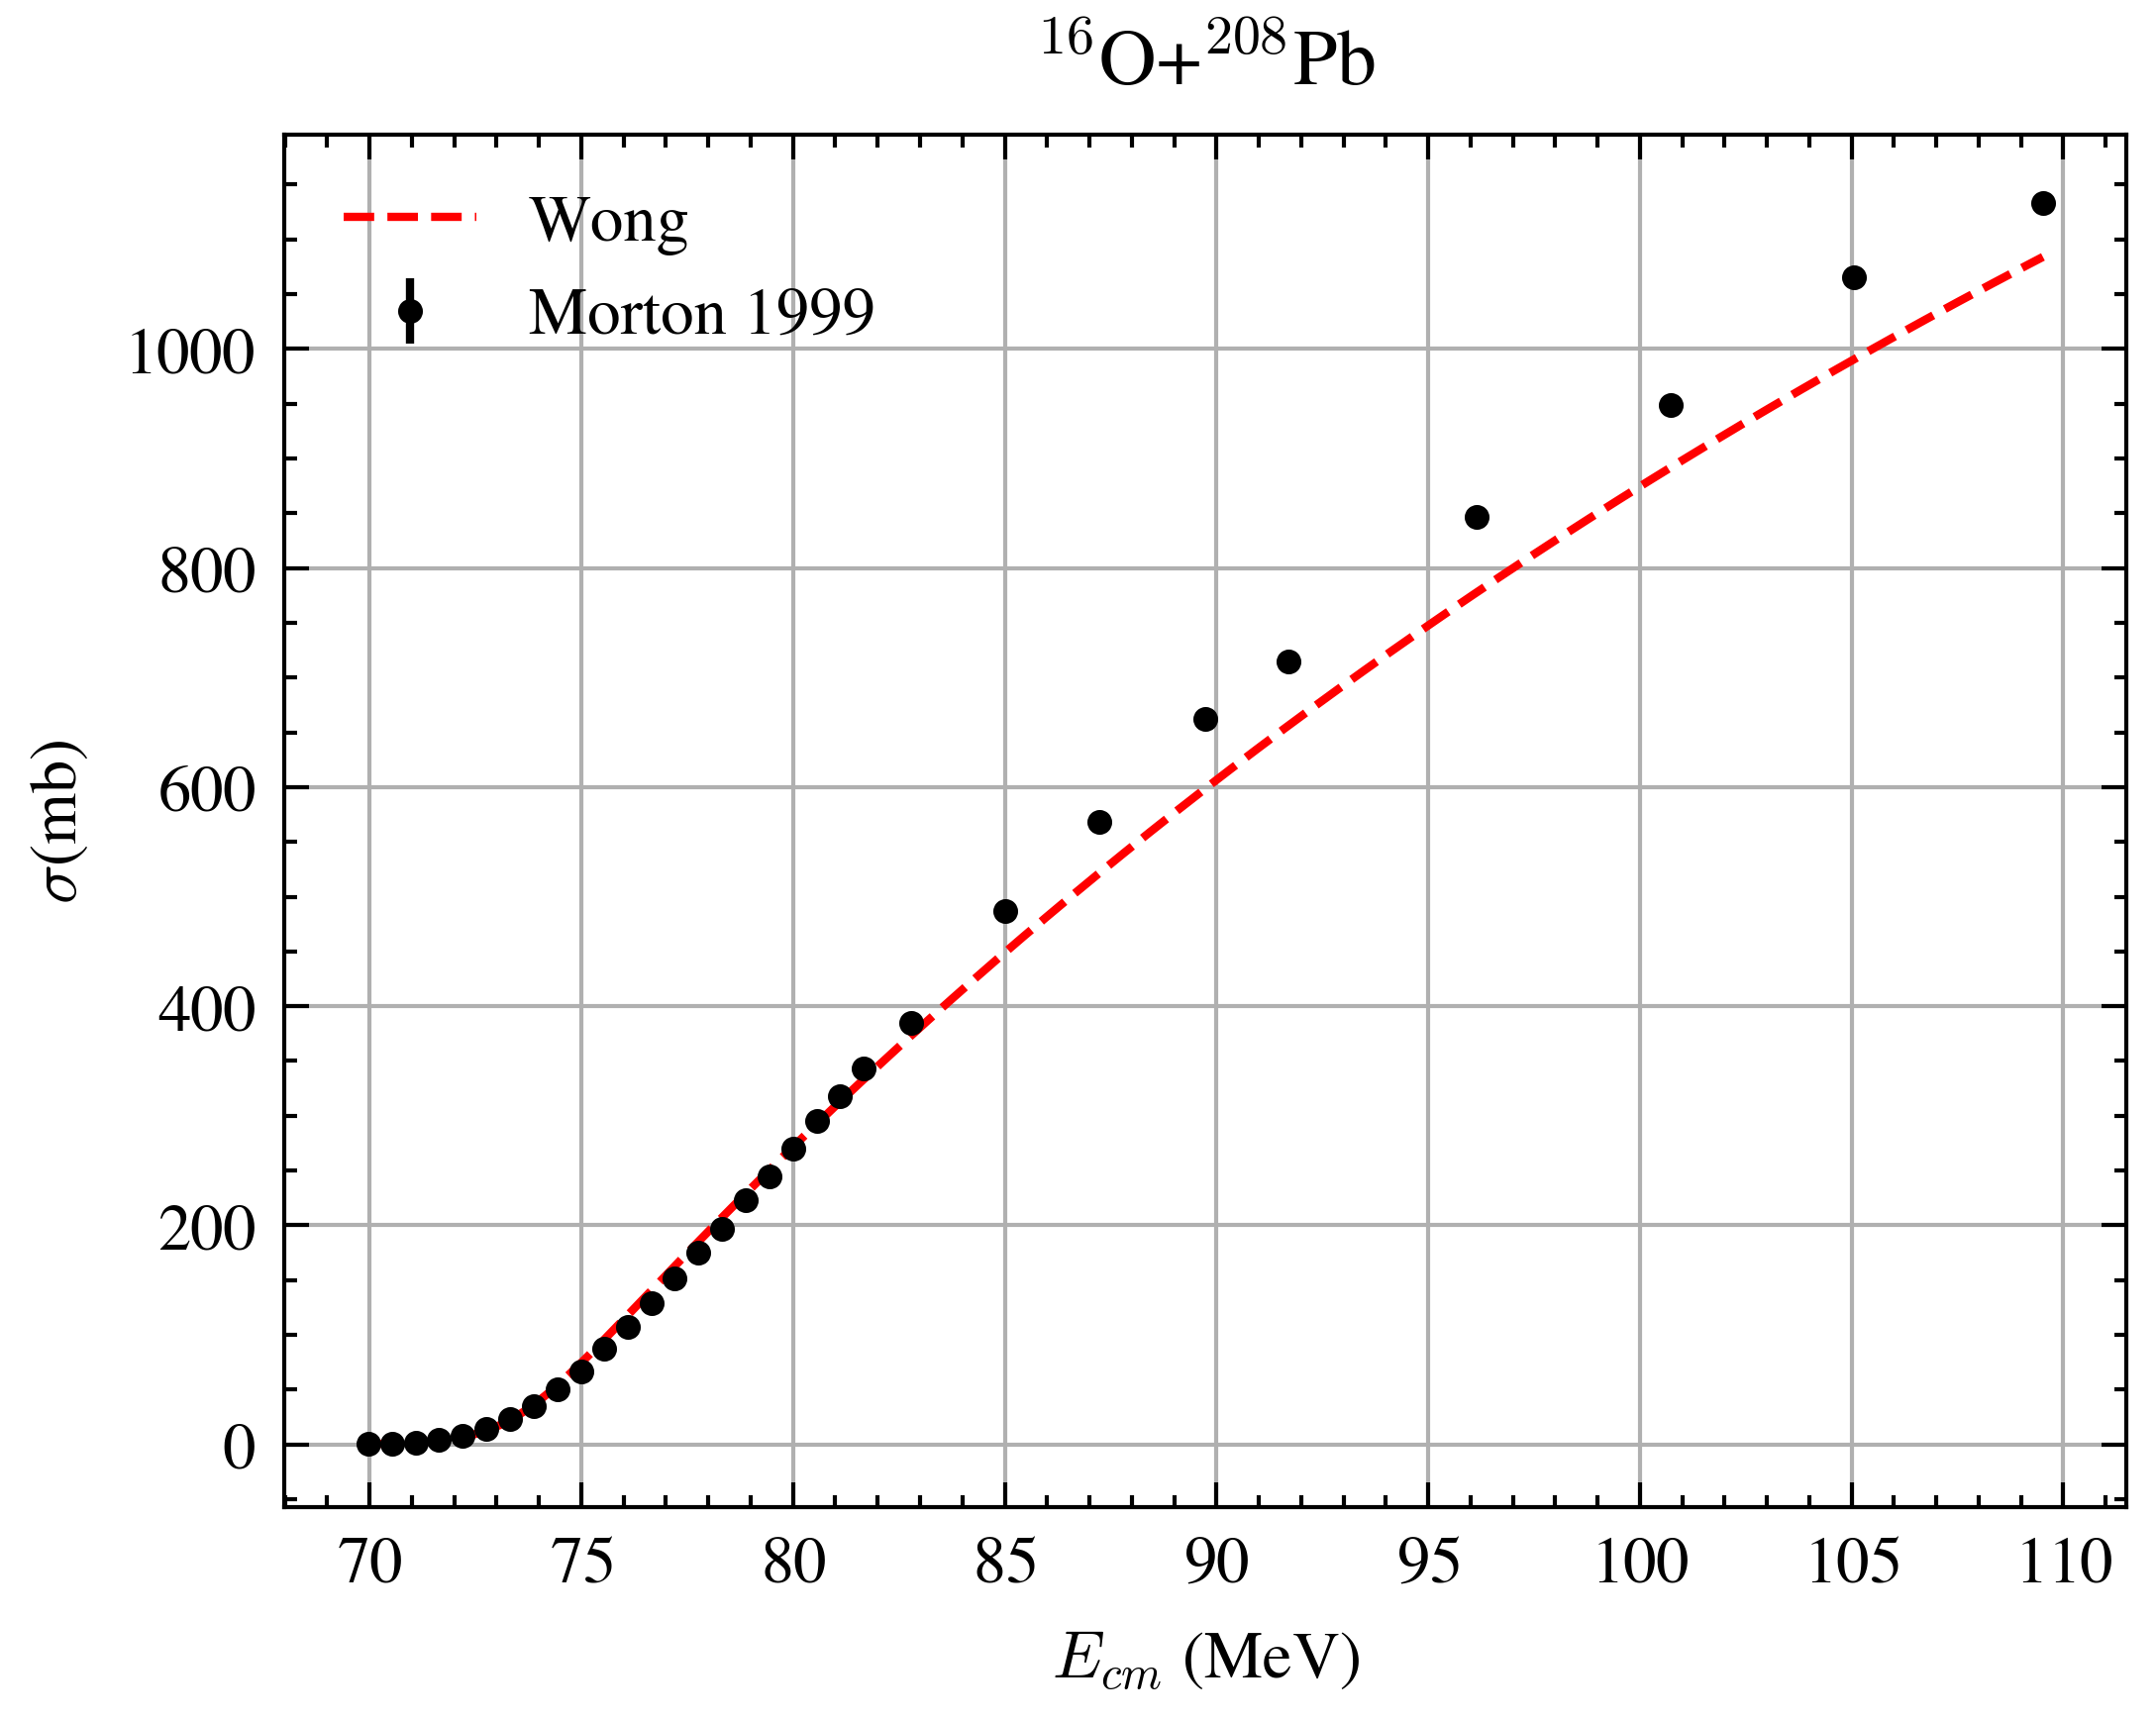

In [3]:
E_data = exp[0]['Ecm'].to_numpy()
Sigma_data = exp[0]['Sigma'].to_numpy()
Sigma_err  = exp[0]['Error'].to_numpy()

# --- Wrapper for curve_fit (it expects signature f(E, *params)) ---
def sigma_fit(E, E0, R0, hbarw):
    return sigma(E, E0, R0, hbarw)

# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess = [70.0, 11.0, 4]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt, pcov = curve_fit(
    sigma_fit,
    E_data,
    Sigma_data,
    p0=initial_guess,
    sigma=Sigma_err,
    absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt, R0_opt, hbarw_opt = popt
perr = np.sqrt(np.diag(pcov))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt:.4f} ± {perr[0]:.4f} MeV")
print(f"  R0    = {R0_opt:.4f} ± {perr[1]:.4f} fm")
print(f"  hbarw = {hbarw_opt:.4f} ± {perr[2]:.4f} MeV")

# --- Plot experiment vs. fit ---
E_plot = np.linspace(E_data.min(), E_data.max(), 500)
Sigma_fit = sigma(E_plot, E0_opt, R0_opt, hbarw_opt)

plt.figure(figsize=(4,3))
plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
#plt.scatter(E_data, Sigma_data, label='Morton 1999', color='k', s=10)
plt.plot(E_plot, Sigma_fit, label='Wong')
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

### Fitted to Dasgupta Data without $\delta \sigma$

Best-fit parameters:
  E0    = 73.3846 ± 0.1716
  R0    = 10.2260 ± 0.0882
  hbarw = 4.8410 ± 1.3627


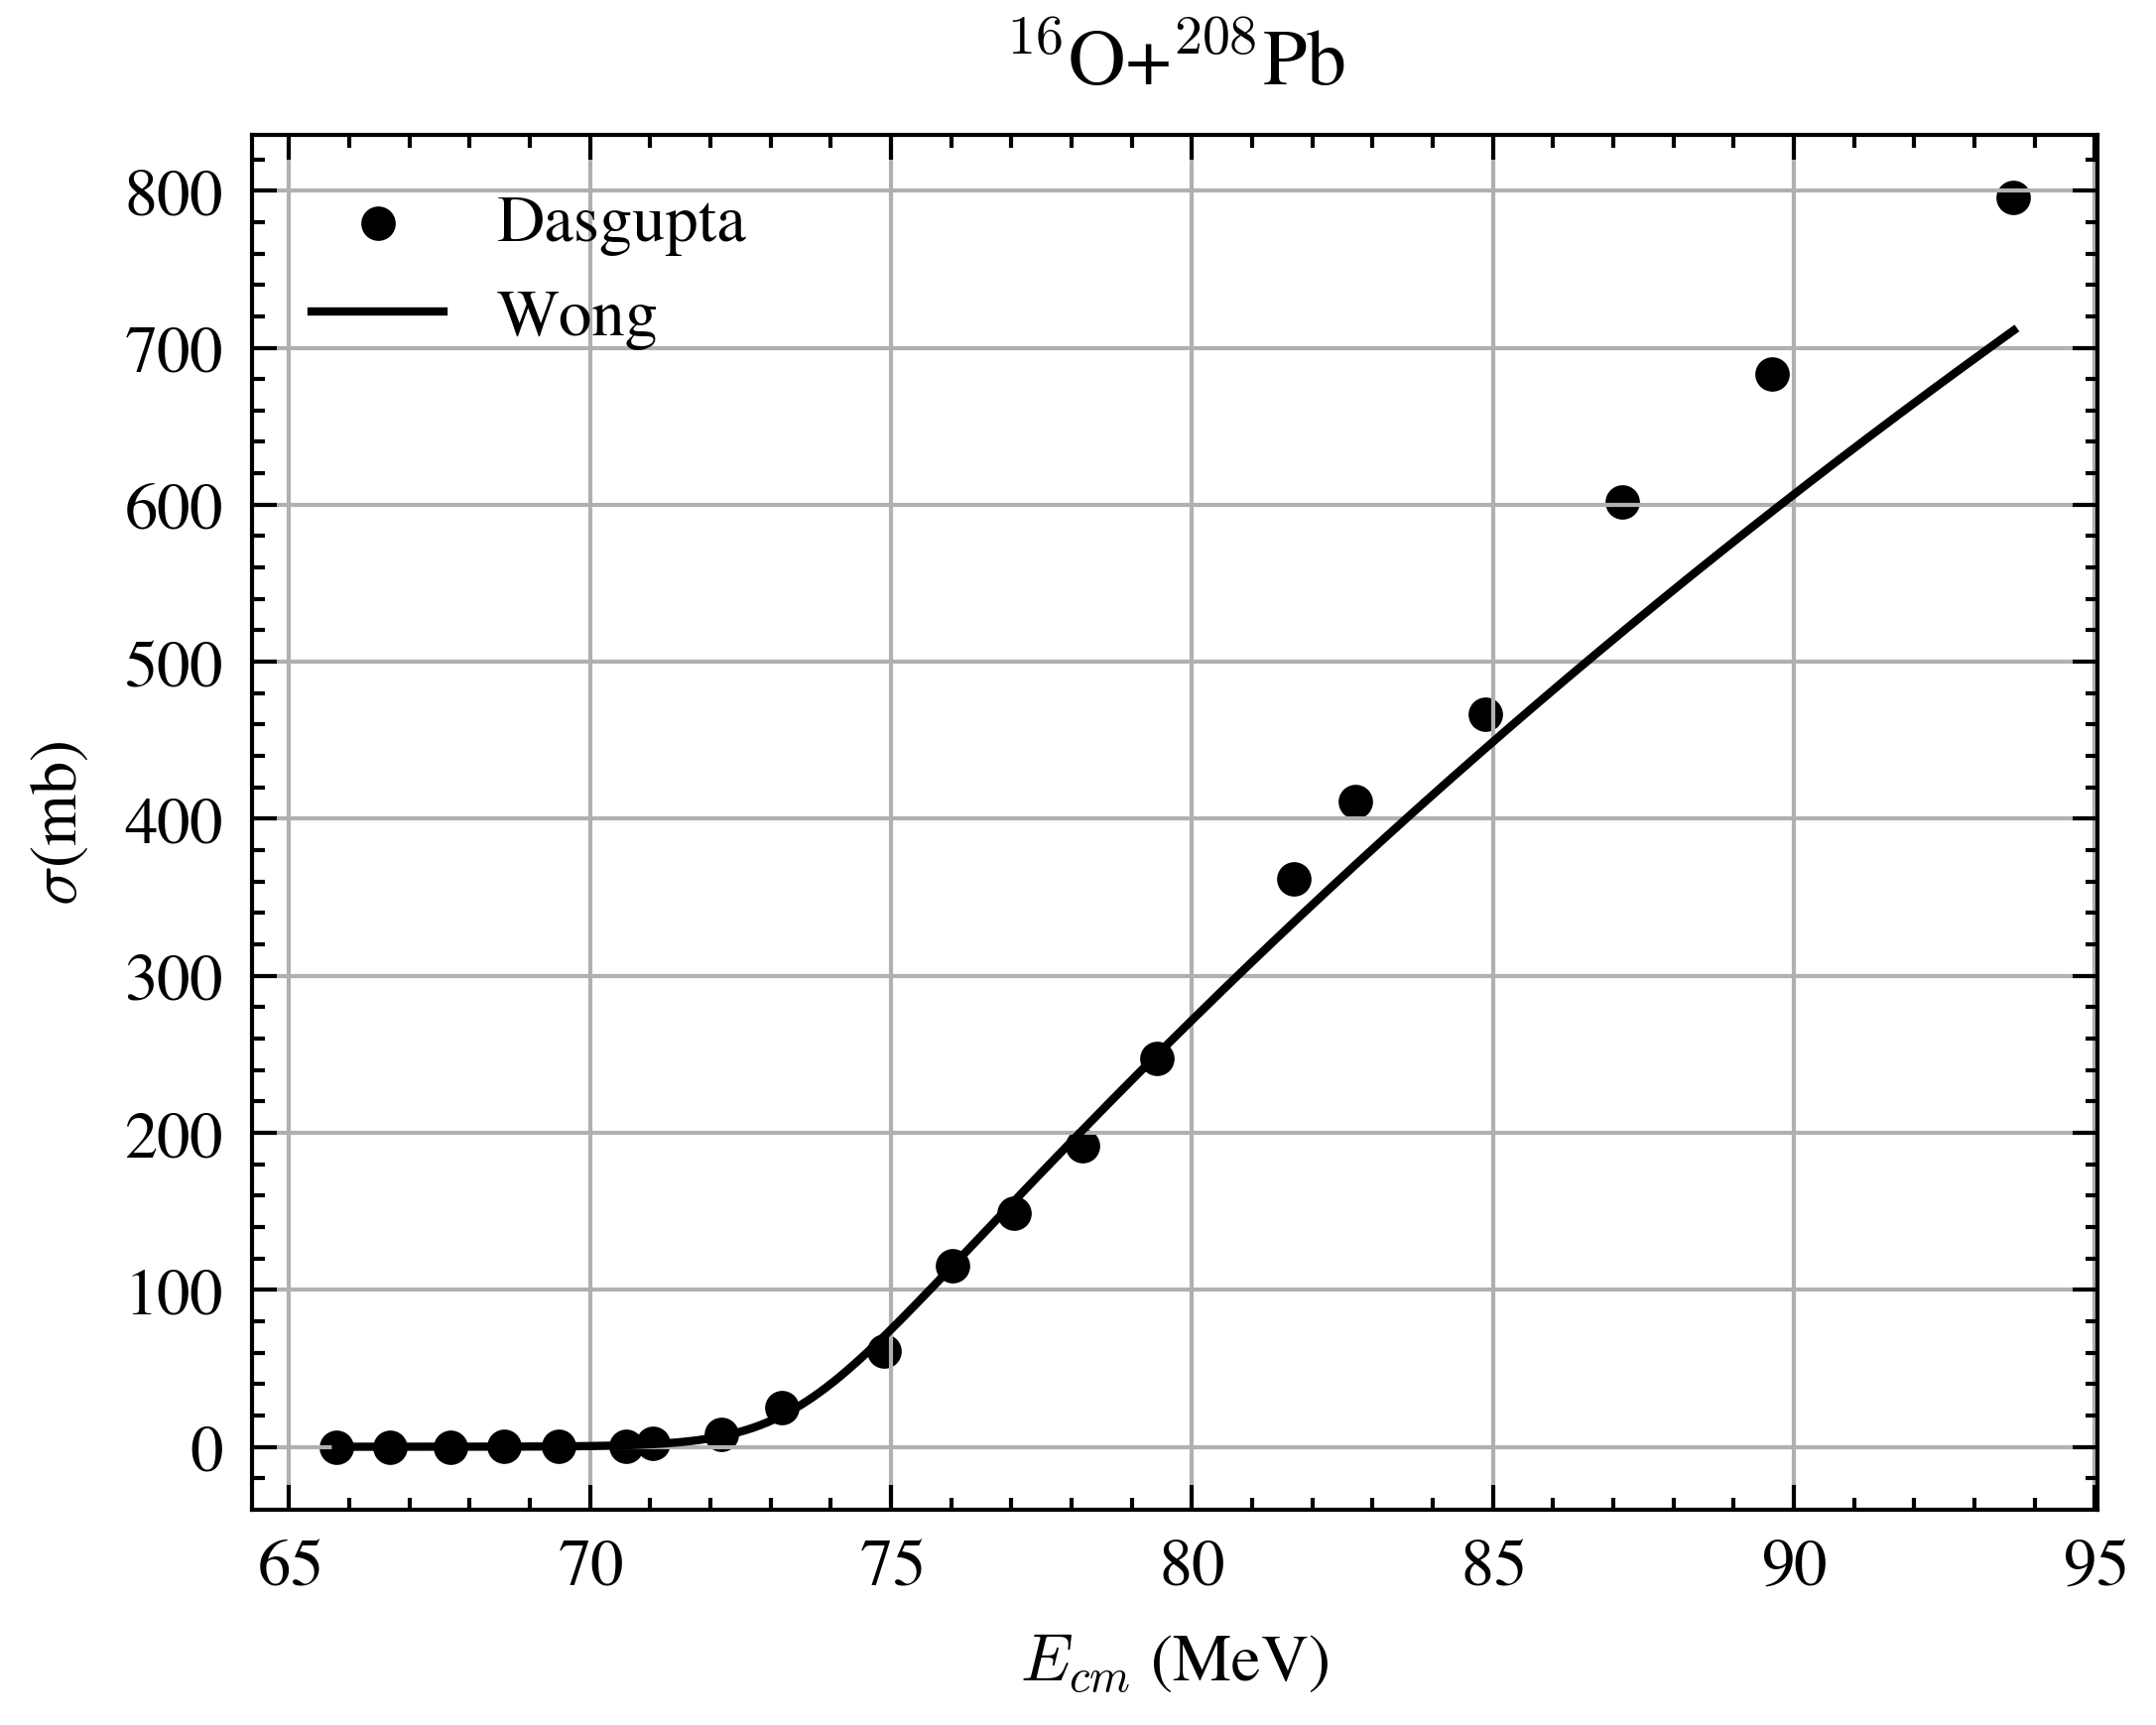

In [4]:
E_data_1 = exp[1]['Ecm'].to_numpy()
Sigma_data_1 = exp[1]['Sigma'].to_numpy()
#Sigma_err  = exp[1]['Error'].to_numpy()

# --- Wrapper for curve_fit (it expects signature f(E, *params)) ---
def sigma_fit(E, E0, R0, hbarw):
    return sigma(E, E0, R0, hbarw)

# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess_1 = [70.0, 11.0, 4]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt_1, pcov_1 = curve_fit(
    sigma_fit,
    E_data_1,
    Sigma_data_1,
    p0=initial_guess_1,
    #sigma=Sigma_err,
    #absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt_1, R0_opt_1, hbarw_opt_1 = popt
perr_1 = np.sqrt(np.diag(pcov_1))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt_1:.4f} ± {perr_1[0]:.4f}")
print(f"  R0    = {R0_opt_1:.4f} ± {perr_1[1]:.4f}")
print(f"  hbarw = {hbarw_opt_1:.4f} ± {perr_1[2]:.4f}")

# --- Plot experiment vs. fit ---
E_plot_1 = np.linspace(E_data_1.min(), E_data_1.max(), 500)
Sigma_fit_1 = sigma(E_plot_1, E0_opt_1, R0_opt_1, hbarw_opt_1)

plt.figure(figsize=(4,3))
#plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
plt.scatter(E_data_1, Sigma_data_1, label='Dasgupta', color='k', s=10)
plt.plot(E_plot_1, Sigma_fit_1, label='Wong')
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

### Sample several reasonable cross sections across fit parameters using the covariance matrix to determine uncertainties

In [5]:
N = 1000
E_fine = np.linspace(E_data.min(), E_data.max(), N)

# Number of Monte‐Carlo draws to propagate parameter‐uncertainty:
M = 200 

# Covariance of (E0,R0,hbarw) from your fit:
P_cov = pcov        # shape (3,3) 

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  1) Draw M parameter‐samples from  N(popt, pcov)                             │
# └─────────────────────────────────────────────────────────────────────────────┘
# Each row of `param_samples` is (E0_j, R0_j, hbarw_j).
param_samples = np.random.multivariate_normal(
    mean=[E0_opt, R0_opt, hbarw_opt],
    cov=P_cov,
    size=M
)  # shape (M,3)

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  2) For each of those M sets, compute σ_j(E_data)                            │
# └─────────────────────────────────────────────────────────────────────────────┘
# We'll build a matrix S of shape (M, N) where
#    S[j,i] = σ( E_fine[i];  E0_j, R0_j, hbarw_j ).
S = np.empty((M, N))

for j in range(M):
    E0_j, R0_j, hbarw_j = param_samples[j]
    # Evaluate your analytic sigma‐function on the entire E_fine grid:
    S[j, :] = sigma(E_fine, E0_j, R0_j, hbarw_j)

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  3) Compute the Monte‐Carlo mean and variance at each E_data[i]               │
# └─────────────────────────────────────────────────────────────────────────────┘
#   mean over j:  shape → (N,)
sigma_mean = S.mean(axis=0)
#   var  over j:  shape → (N,)
sigma_var  = S.var(axis=0, ddof=1)   # unbiased estimate of Var[σ(E_i)]

# If any σ_var[i] happens to be exactly zero (i.e. all S[:,i] identical),
# add a tiny floor so the GP doesn't complain about zero‐noise.
sigma_var += 1e-16

In [26]:
from train import train_gp
from plot import plot_gp_with_data

# Create a training set for the GP:
interval = 10
start =0
stop = np.argmin(np.abs(E_fine - 90.0))
E_train = E_fine[start:stop:interval]
sigma_train = sigma_mean[start:stop:interval]
sigma_train_var = sigma_var[start:stop:interval]
gp = train_gp(E_train, sigma_train, sigma_train_var)


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


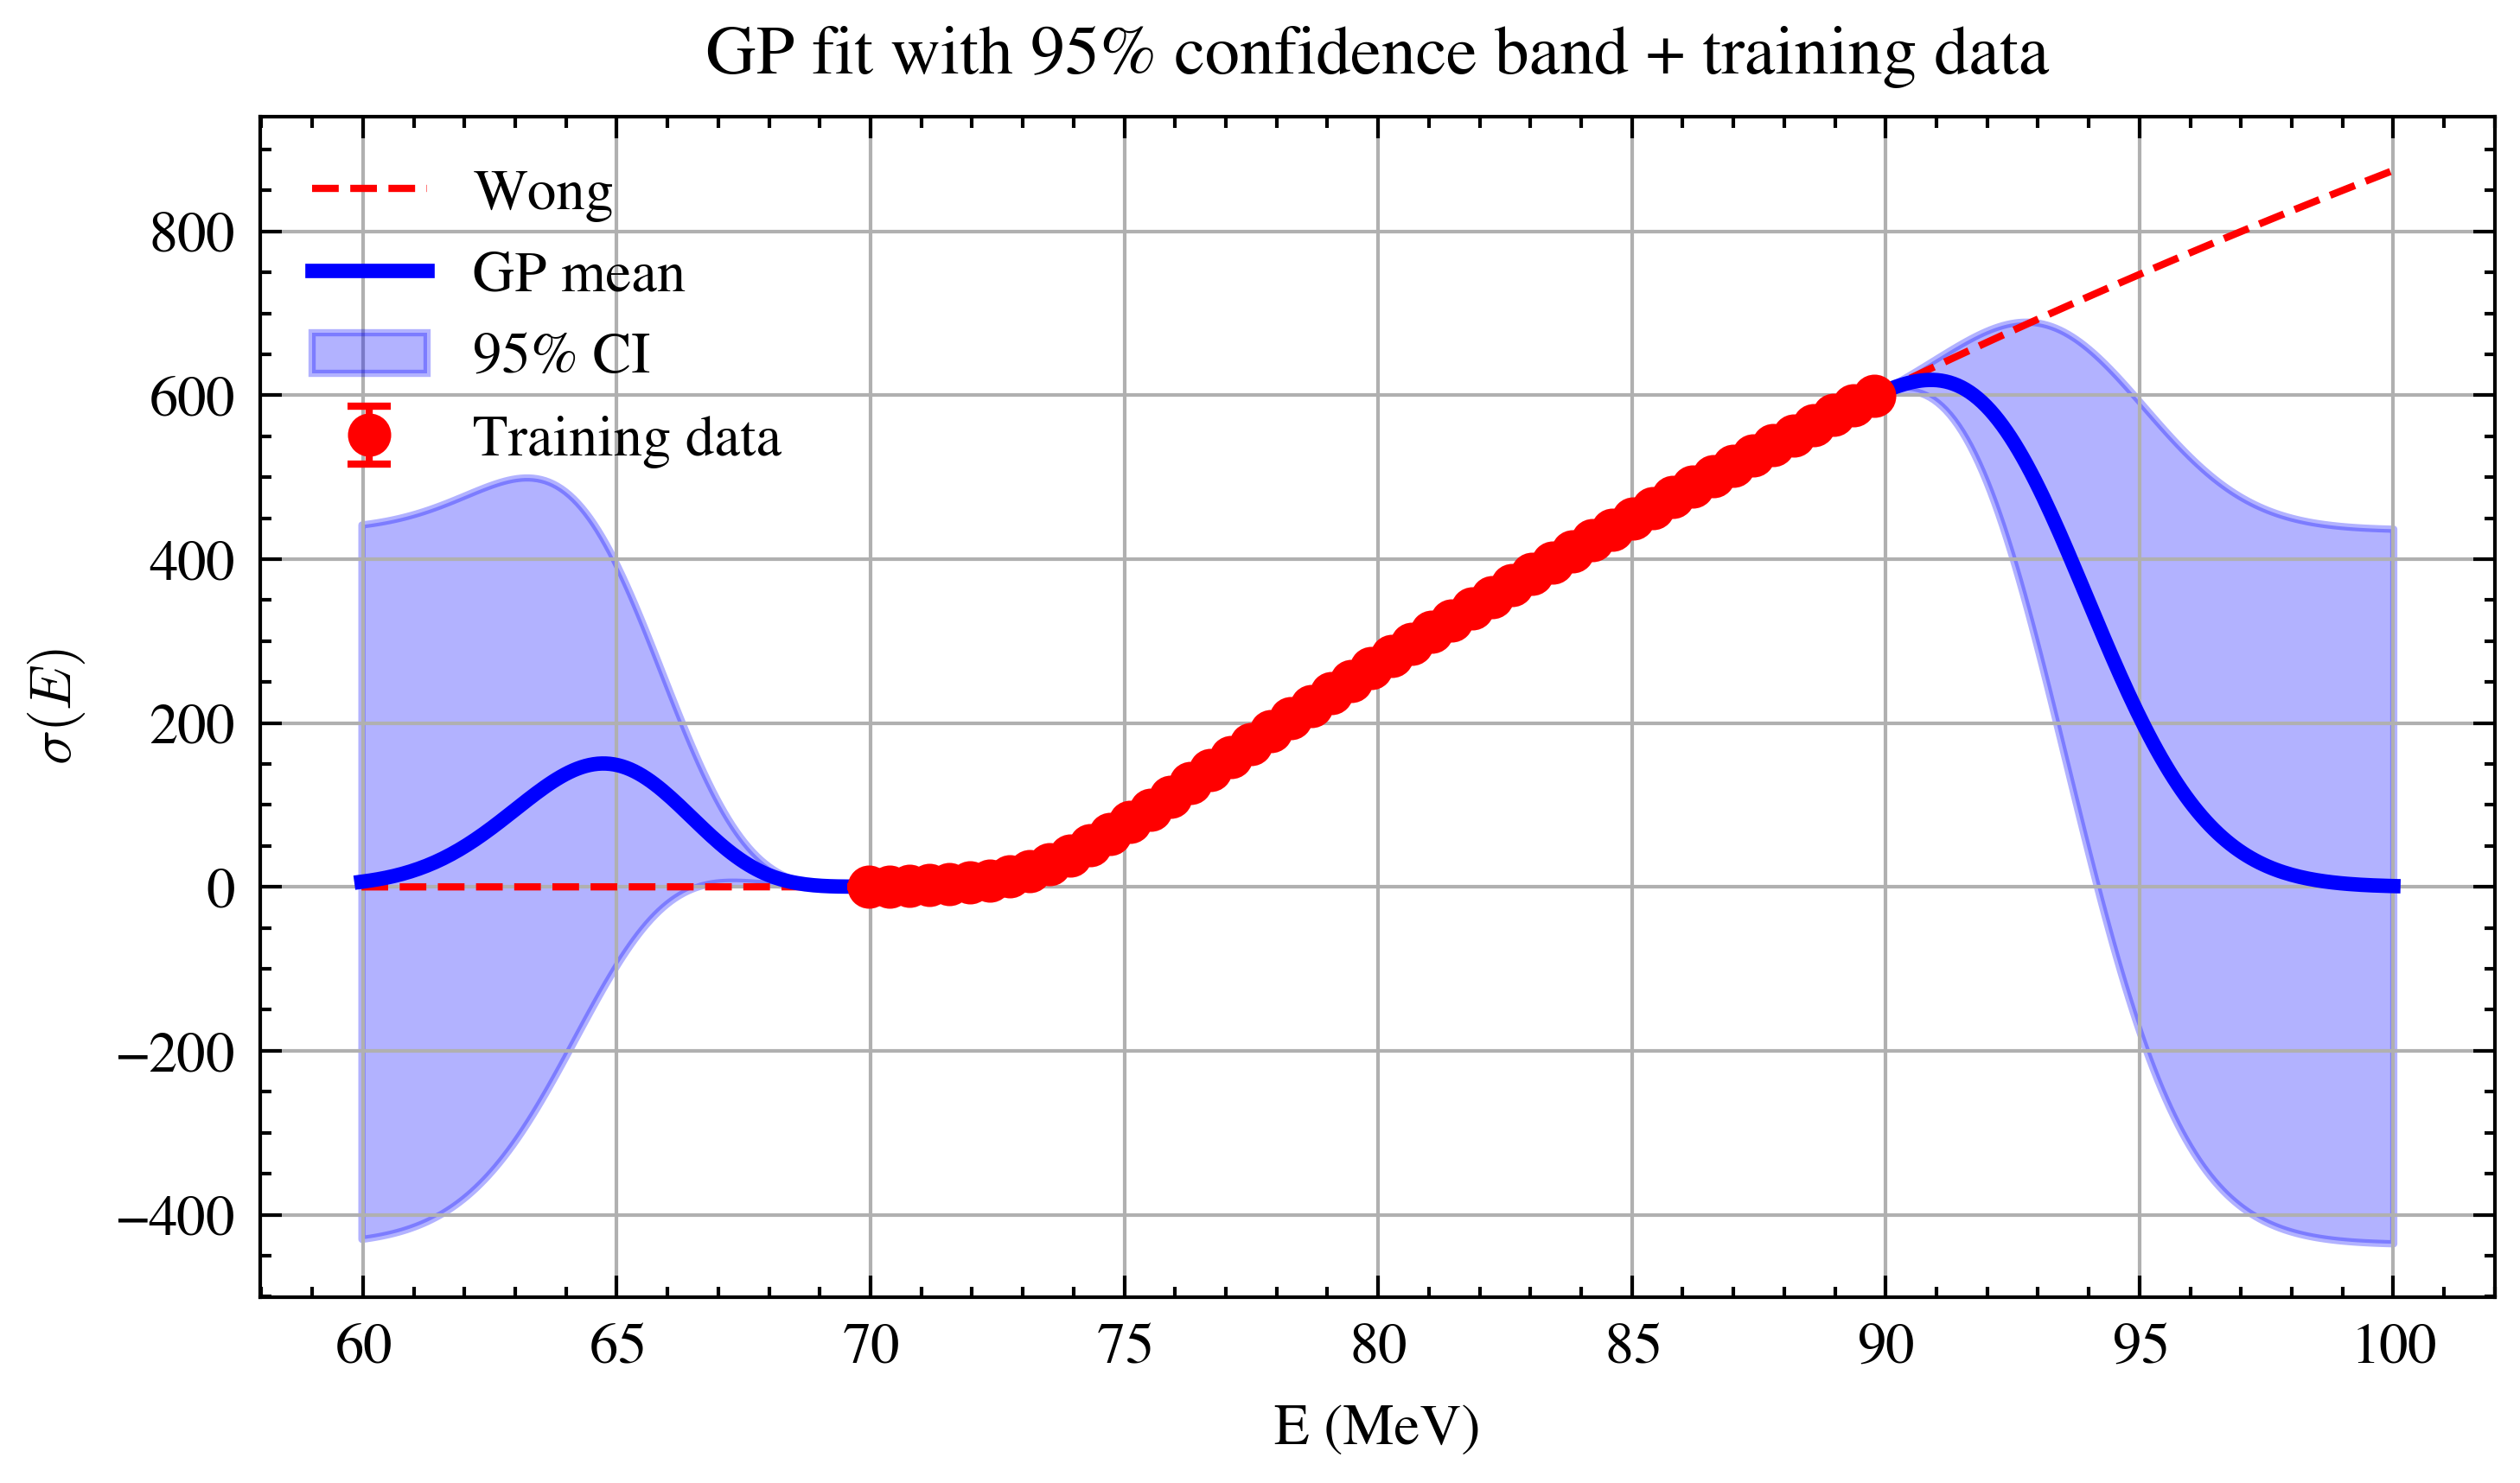

In [27]:
E_eval = np.linspace(E_data.min()-10, 100, 500)
# Plot the GP with the training data and the uncertainty:
plt.figure(figsize=(5, 3))
plt.plot(E_eval, sigma(E_eval, E0_opt, R0_opt, hbarw_opt), label='Wong', color='C1', linestyle='--')
plot_gp_with_data(gp, E_plot=E_eval, E_train=E_train, sigma_mu_train=sigma_train, delta_sigma_train=sigma_train_var)

plt.show()

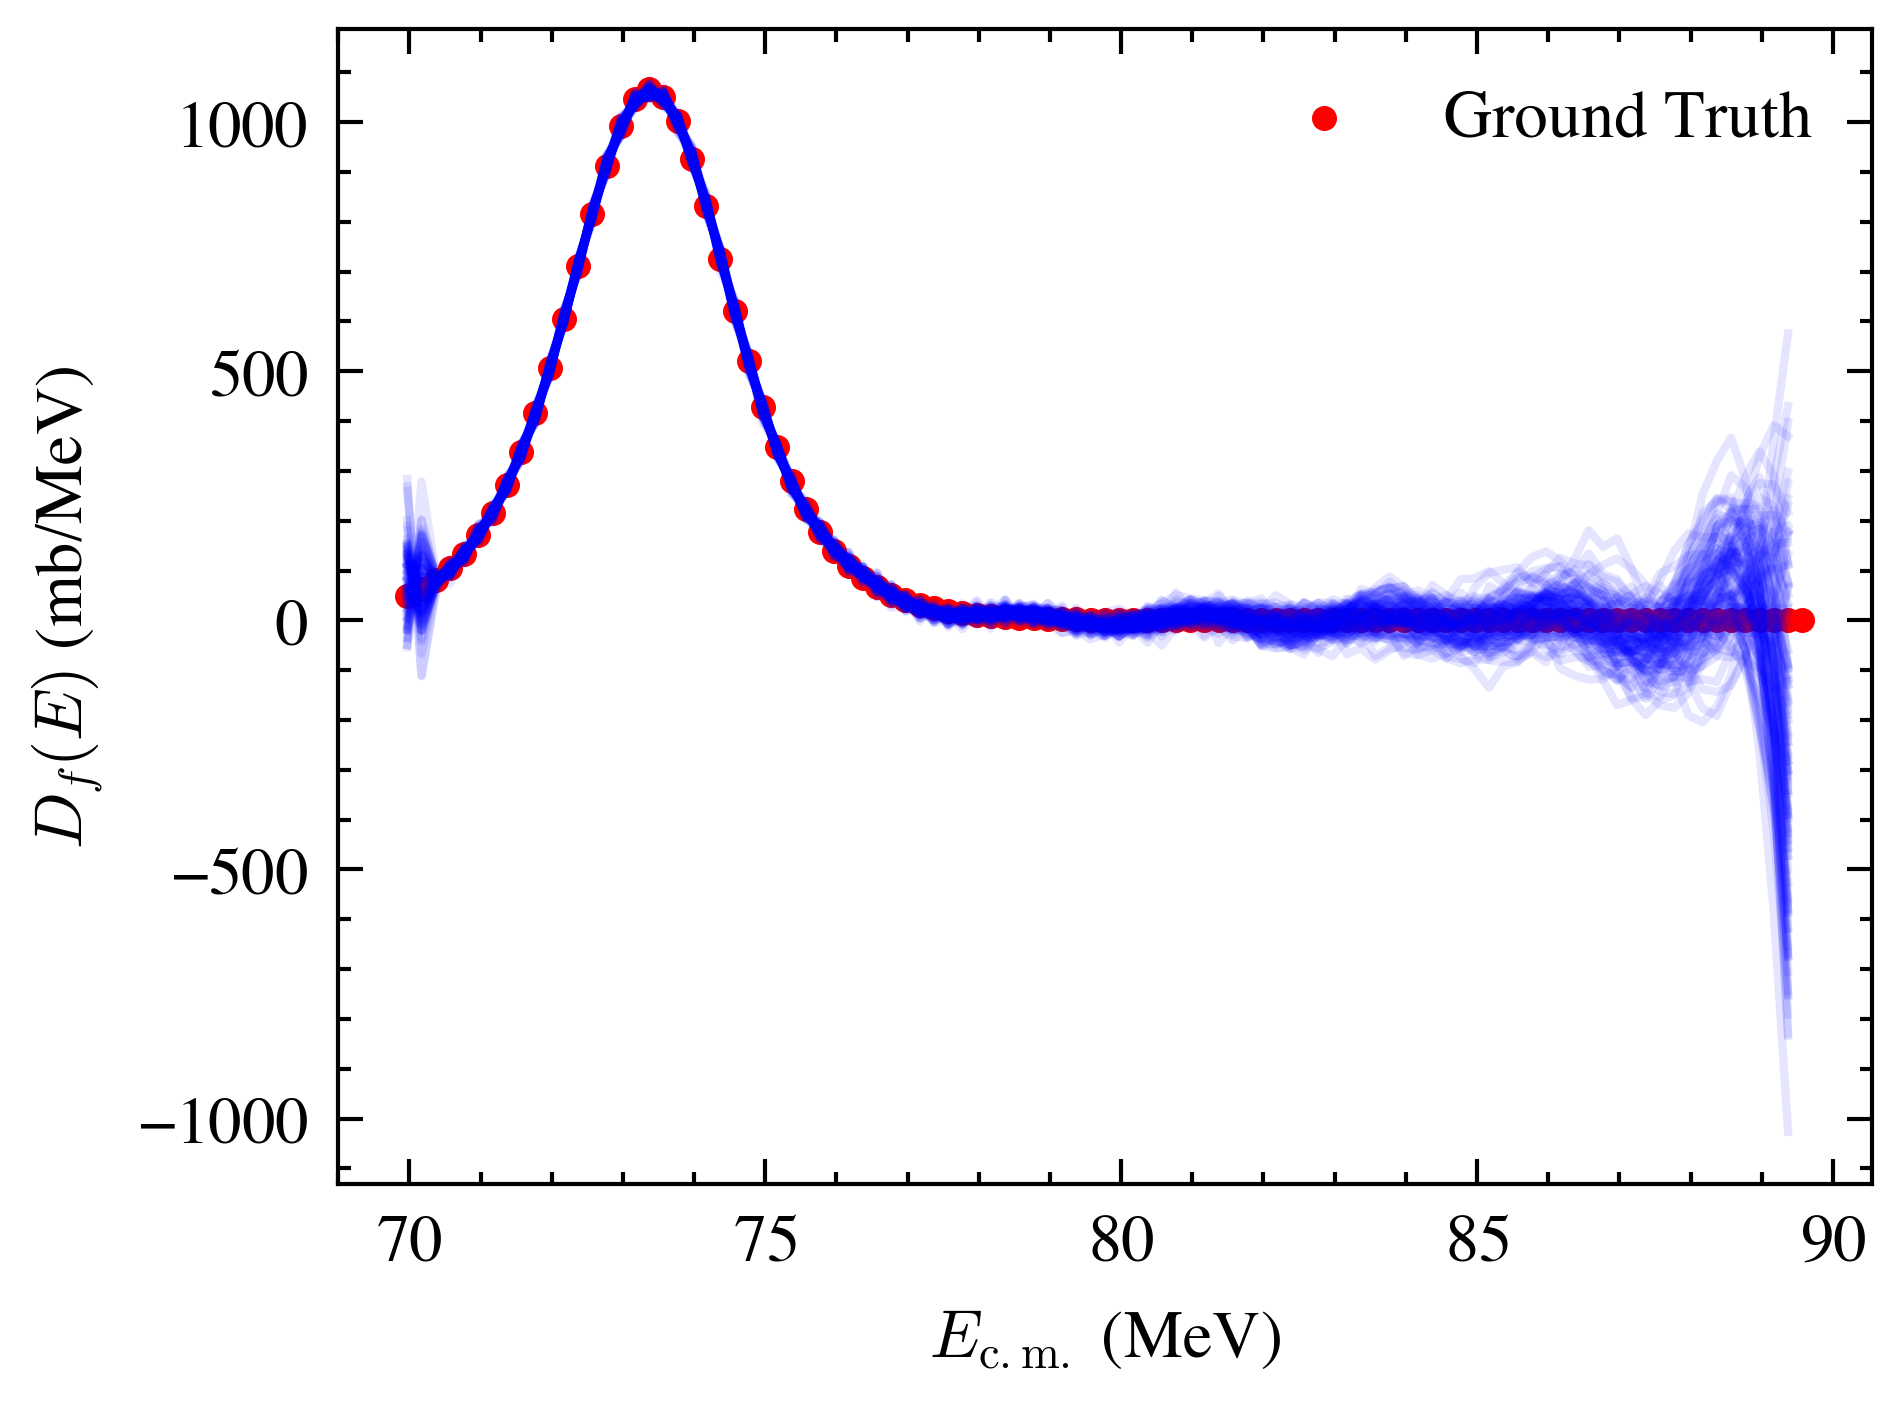

In [89]:
from utils import barrier_dist
E_dist = np.arange(E_train[0],E_train[-1], 0.2)
n_samples=100
n_cut=0
y_samples = gp.sample_y(E_dist.reshape(-1,1), n_samples=n_samples)
ndist = np.zeros((len(E_dist),n_samples))
for i in range(n_samples):
    ndist[:,i] = barrier_dist(E_dist,y_samples[:,i],acc=4)
    plt.plot(E_dist[n_cut:-n_cut-1],ndist[n_cut:-n_cut-1,i],marker="",ls='-',lw=1,ms=0,alpha=0.1, color='b')
true = barrier_dist(E_dist,sigma(E_dist,E0_opt,R0_opt,hbarw_opt),acc=4)
#plt.plot(E_dist[5:-5:10],true[5:-5:10],linestyle='--',color='r',label=r'True $D_{f}(E)$')
spacing = 1
plt.scatter(E_dist[::spacing],true[::spacing],marker='o',color='r',label=r'Ground Truth', s=4)

plt.legend()
plt.ylabel(r'$D_f(E)$ (mb/MeV)')
plt.xlabel(r'$E_{\mathrm{c.m.}}$ (MeV)')
plt.show()


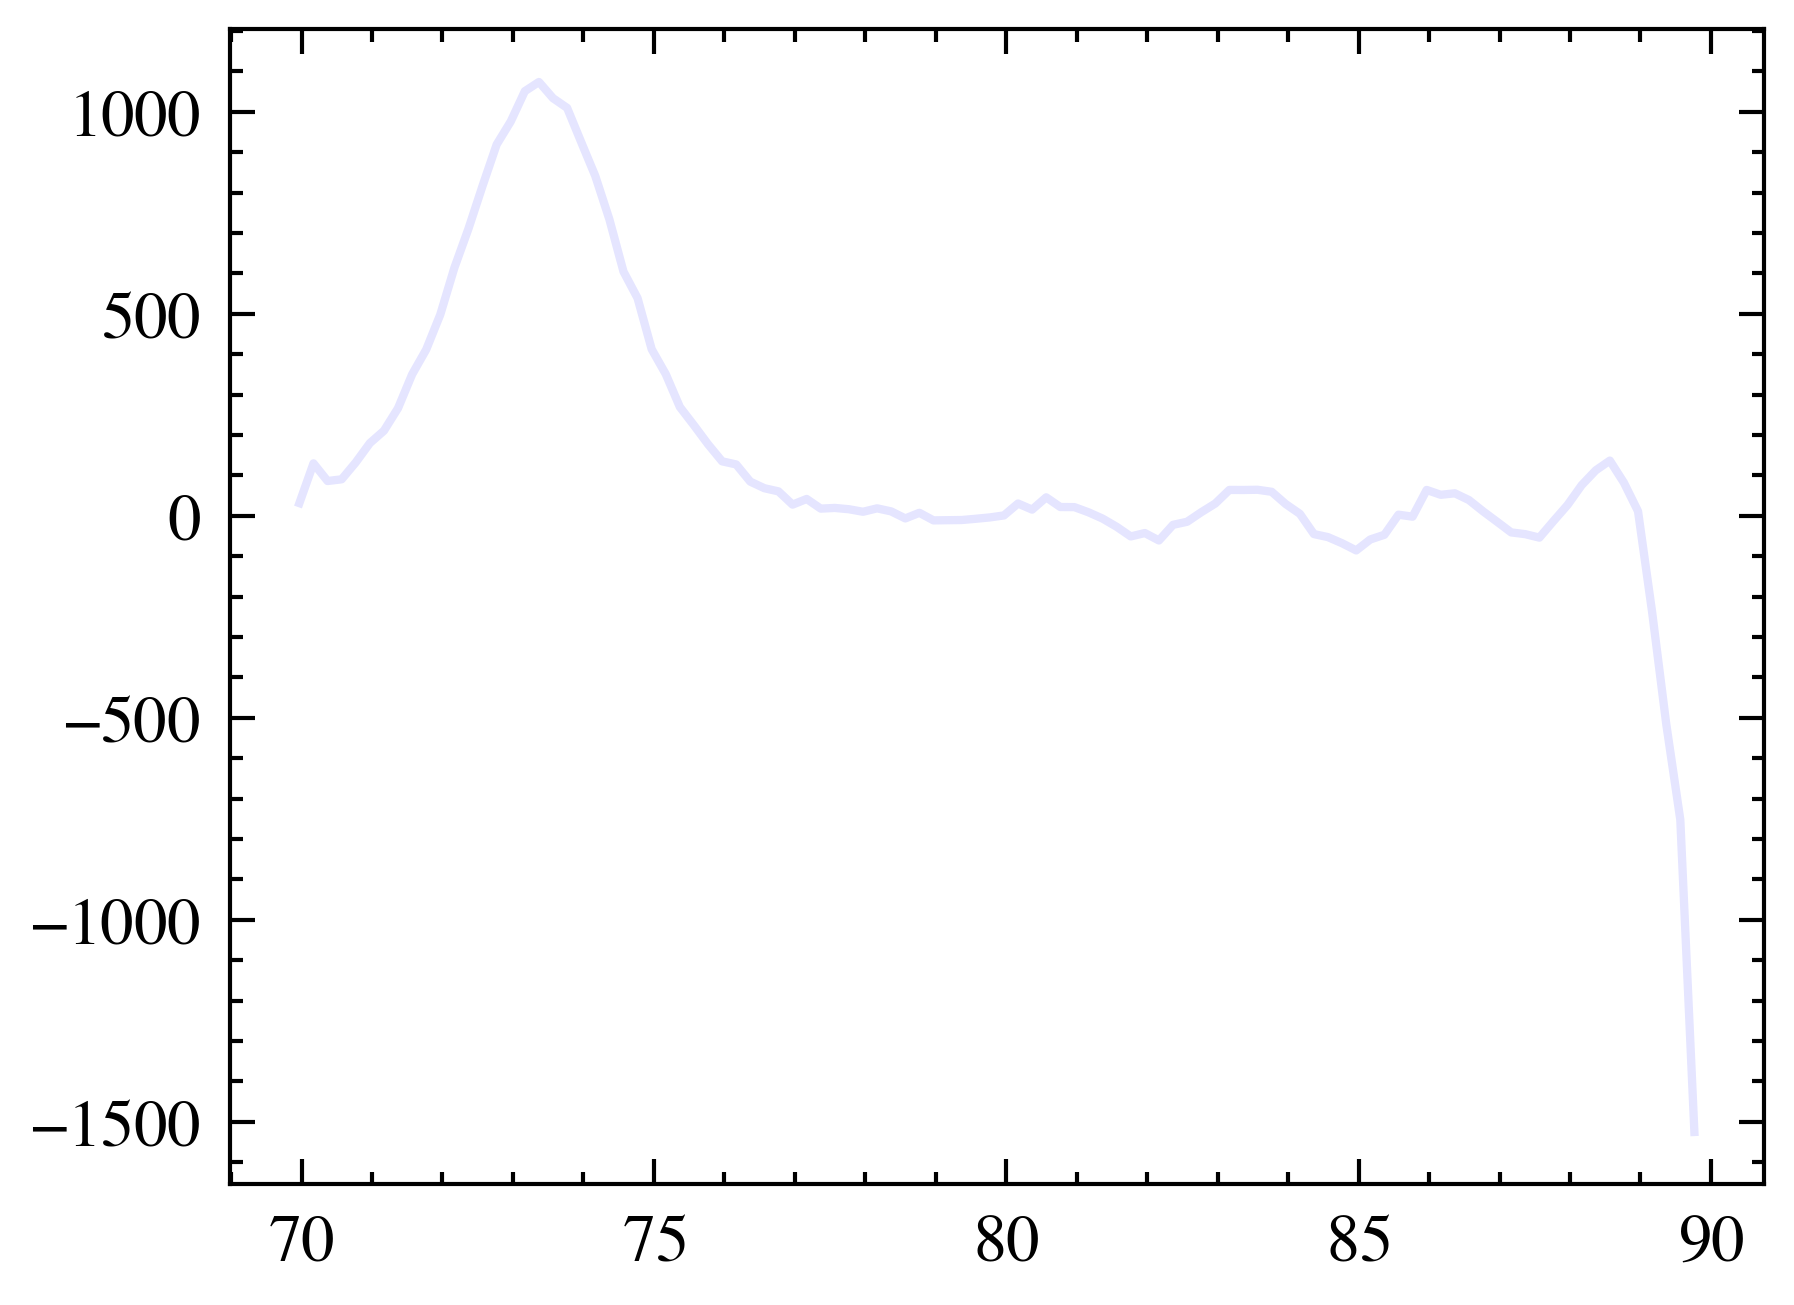

In [60]:
plt.plot(E_dist,ndist[:,5],marker="",ls='-',lw=1,ms=0,alpha=0.1, color='b')